In [118]:
import pandas as pd
import numpy as np


In [119]:
sample0_filepath = "../Data/training_data/mixed_samples/0healthy.npy"
sample0 = np.load(sample0_filepath)
sample0.shape

# (frame, points, position)
# (10, 18000, 4)


(10, 18000, 4)

In [120]:
sample0

array([[[-20.157444  ,  17.62280464,   8.63055611,   2.        ],
        [-20.09103012,  17.62147141,   8.63197422,   2.        ],
        [-20.10420418,  17.62444115,   8.61793327,   2.        ],
        ...,
        [-17.84309578, -33.76960754,  53.19683838,   1.        ],
        [-16.25856209, -35.0315094 ,  57.05285645,   1.        ],
        [-15.38268089, -35.53833008,  59.0874176 ,   1.        ]],

       [[-19.19090843,  17.49430275,   9.2532053 ,   2.        ],
        [-19.11496544,  17.52137566,   9.26454735,   2.        ],
        [-19.10906029,  17.52939224,   9.25193214,   2.        ],
        ...,
        [-17.47473717, -31.39459229,  49.87592697,   1.        ],
        [-16.00337601, -32.55651855,  53.38047791,   1.        ],
        [-15.19591618, -32.96632385,  55.38721085,   1.        ]],

       [[-18.31469727,  14.26771927,   9.15201092,   2.        ],
        [-18.25457001,  14.28464699,   9.16969109,   2.        ],
        [-18.26982689,  14.30463123,   9.16434

In [121]:
import pymeshlab

ms = pymeshlab.MeshSet()

In [122]:
import plotly.express as px

one_frame = sample0[0, :, :]

for i in range(0, 10, 3):
    frame = sample0[i, :, :]
    px.scatter_3d(x=frame[:,0], y=frame[:,1], z=frame[:,2], color=frame[:,3], width=400, height=400).update_traces(marker_size=2).show()

# px.scatter_3d(x=one_frame[:,0], y=one_frame[:,1], z=one_frame[:,2], color=one_frame[:,3]).update_traces(marker_size=2).show()


In [123]:
tabular_filepath = "../Data/training_data/mixed_demographics.csv"


tabular = pd.read_csv(tabular_filepath)

{'whiskers': [<matplotlib.lines.Line2D at 0x3e9ba0980>,
 'caps': [<matplotlib.lines.Line2D at 0x3e9ba0c20>,
 'boxes': [<matplotlib.lines.Line2D at 0x3e9ba0830>,
 'medians': [<matplotlib.lines.Line2D at 0x3e9ba0ec0>,
 'fliers': [<matplotlib.lines.Line2D at 0x3e9ba1010>,
 'means': []}

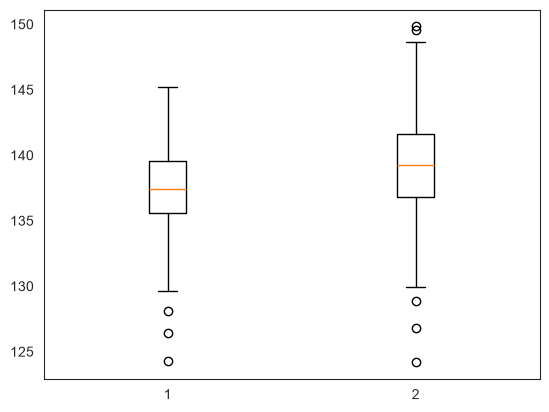

In [124]:
import matplotlib.pyplot as plt

healthy = tabular[tabular['MI'] == "healthy"]
pMI = tabular[tabular['MI'] == "pMI"]

plt.boxplot((healthy['systolic_BP'], pMI['systolic_BP']))


{'whiskers': [<matplotlib.lines.Line2D at 0x3e9b50ad0>,
 'caps': [<matplotlib.lines.Line2D at 0x3e9b50d70>,
 'boxes': [<matplotlib.lines.Line2D at 0x3e9b50980>,
 'medians': [<matplotlib.lines.Line2D at 0x3e9b51010>,
 'fliers': [<matplotlib.lines.Line2D at 0x3e9b51160>,
 'means': []}

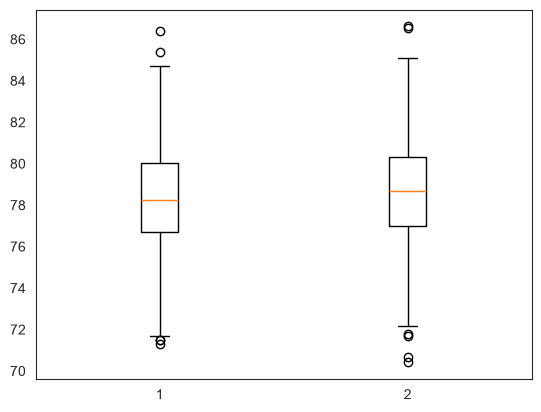

In [125]:
plt.boxplot((healthy['diastolic_BP'], pMI['diastolic_BP']))


{'whiskers': [<matplotlib.lines.Line2D at 0x3f8799940>,
 'caps': [<matplotlib.lines.Line2D at 0x3f8799be0>,
 'boxes': [<matplotlib.lines.Line2D at 0x3f87997f0>,
 'medians': [<matplotlib.lines.Line2D at 0x3f8799e80>,
 'fliers': [<matplotlib.lines.Line2D at 0x3f8799fd0>,
 'means': []}

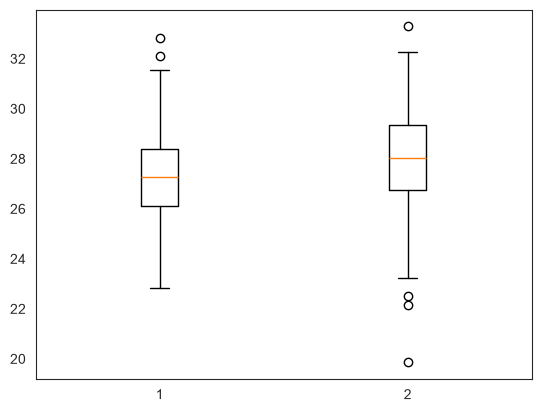

In [126]:
plt.boxplot((healthy['BMI'], pMI['BMI']))


# PCA Exploration

In [127]:
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split


In [128]:
one_frame.flatten()

array([-20.157444  ,  17.62280464,   8.63055611, ..., -35.53833008,
        59.0874176 ,   1.        ], shape=(72000,))

In [129]:
import os

folder = "../Data/training_data/mixed_samples/"

train = os.listdir(folder)

data = np.ndarray((len(train), 72000))

for i, file in enumerate(train):
    sample = np.load(os.path.join(folder, file))

    frame_one = sample[3, :, :]
    frame_two = sample[4, :, :]

    velocity = frame_two - frame_one

    data[i] = velocity.flatten()

data

array([[ 0.14428425,  0.89783955, -0.70751572, ..., -0.33858109,
         1.21946335,  0.        ],
       [-0.14806938, -0.22689438,  0.795681  , ..., -0.03645706,
         0.76172256,  0.        ],
       [ 0.13169098, -0.85699177, -0.327672  , ..., -0.40065765,
        -0.91302872,  0.        ],
       ...,
       [ 0.08533001,  0.85106754, -0.28015232, ..., -0.18115997,
         0.50621033,  0.        ],
       [-0.76700974, -0.04349327,  0.39994621, ..., -1.41813087,
         0.89609909,  0.        ],
       [ 0.62447548,  1.33470249, -0.241745  , ...,  0.24065781,
        -0.10497284,  0.        ]], shape=(900, 72000))

In [130]:


pca = PCA()
pca.fit(data)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [131]:
sd = np.sqrt(pca.explained_variance_)
prop = pca.explained_variance_ratio_
cum = np.cumsum(prop)

summary = pd.DataFrame({
    "Std dev.": sd,
    "Prop. var": prop,
    "Cum. prop": cum
}, index=[f"Comp.{i+1}" for i in range(len(sd))]).round(6)
summary

,Std dev.,Prop. var,Cum. prop
Comp.1,628.818186,0.495284,0.495284
Comp.2,188.831463,0.044663,0.539947
Comp.3,164.956438,0.034083,0.574031
Comp.4,89.394918,0.010010,0.584041
Comp.5,89.357220,0.010001,0.594042
...,...,...,...
Comp.896,0.012891,0.000000,1.000000
Comp.897,0.010875,0.000000,1.000000
Comp.898,0.009454,0.000000,1.000000
Comp.899,0.006901,0.000000,1.000000


After 61 PCA, have 99% of the cumulative variance. 

In [132]:
import seaborn as sns

scores = pca.transform(data)
scores_df_raw = pd.DataFrame(scores, columns=[f"PC{i+1}" for i in range(scores.shape[1])])

scores_df = scores_df_raw.drop([f"PC{i+1}" for i in range(5, scores.shape[1])], axis=1)


In [133]:
scores_df['age'] = tabular["age"]
scores_df['BMI'] = tabular["BMI"]
scores_df['sex'] = tabular["sex"]
scores_df['systolic_BP'] = tabular["systolic_BP"]

scores_df

,PC1,PC2,PC3,PC4,PC5,age,BMI,sex,systolic_BP
0,141.643386,-226.928612,61.360148,-6.333202,-6.754771,62.593012,25.312186,False,137.765801
1,119.432171,-96.122224,15.504639,9.662159,-5.412184,58.037959,32.100795,False,143.459426
2,-68.283250,29.849467,-8.823973,1.774460,-3.667021,65.840496,26.099055,False,137.100866
3,166.830591,-297.504602,86.061626,8.171473,-8.431263,68.518300,27.672836,True,140.518093
4,160.565267,-245.548306,51.448851,-494.097311,916.677176,55.591381,27.266429,False,133.740780
...,...,...,...,...,...,...,...,...,...
895,469.629533,-542.238965,139.376825,-1.207627,-12.942836,68.332345,26.048104,True,138.305894
896,-169.712081,254.342899,-82.506438,0.034337,1.444639,64.392429,28.965176,False,141.375206
897,106.144260,-146.295534,35.346428,-0.932593,-6.088734,63.653352,26.534891,True,137.919129
898,18.334320,-65.037207,17.075534,11.570507,-2.530570,66.775260,27.679240,True,141.577103


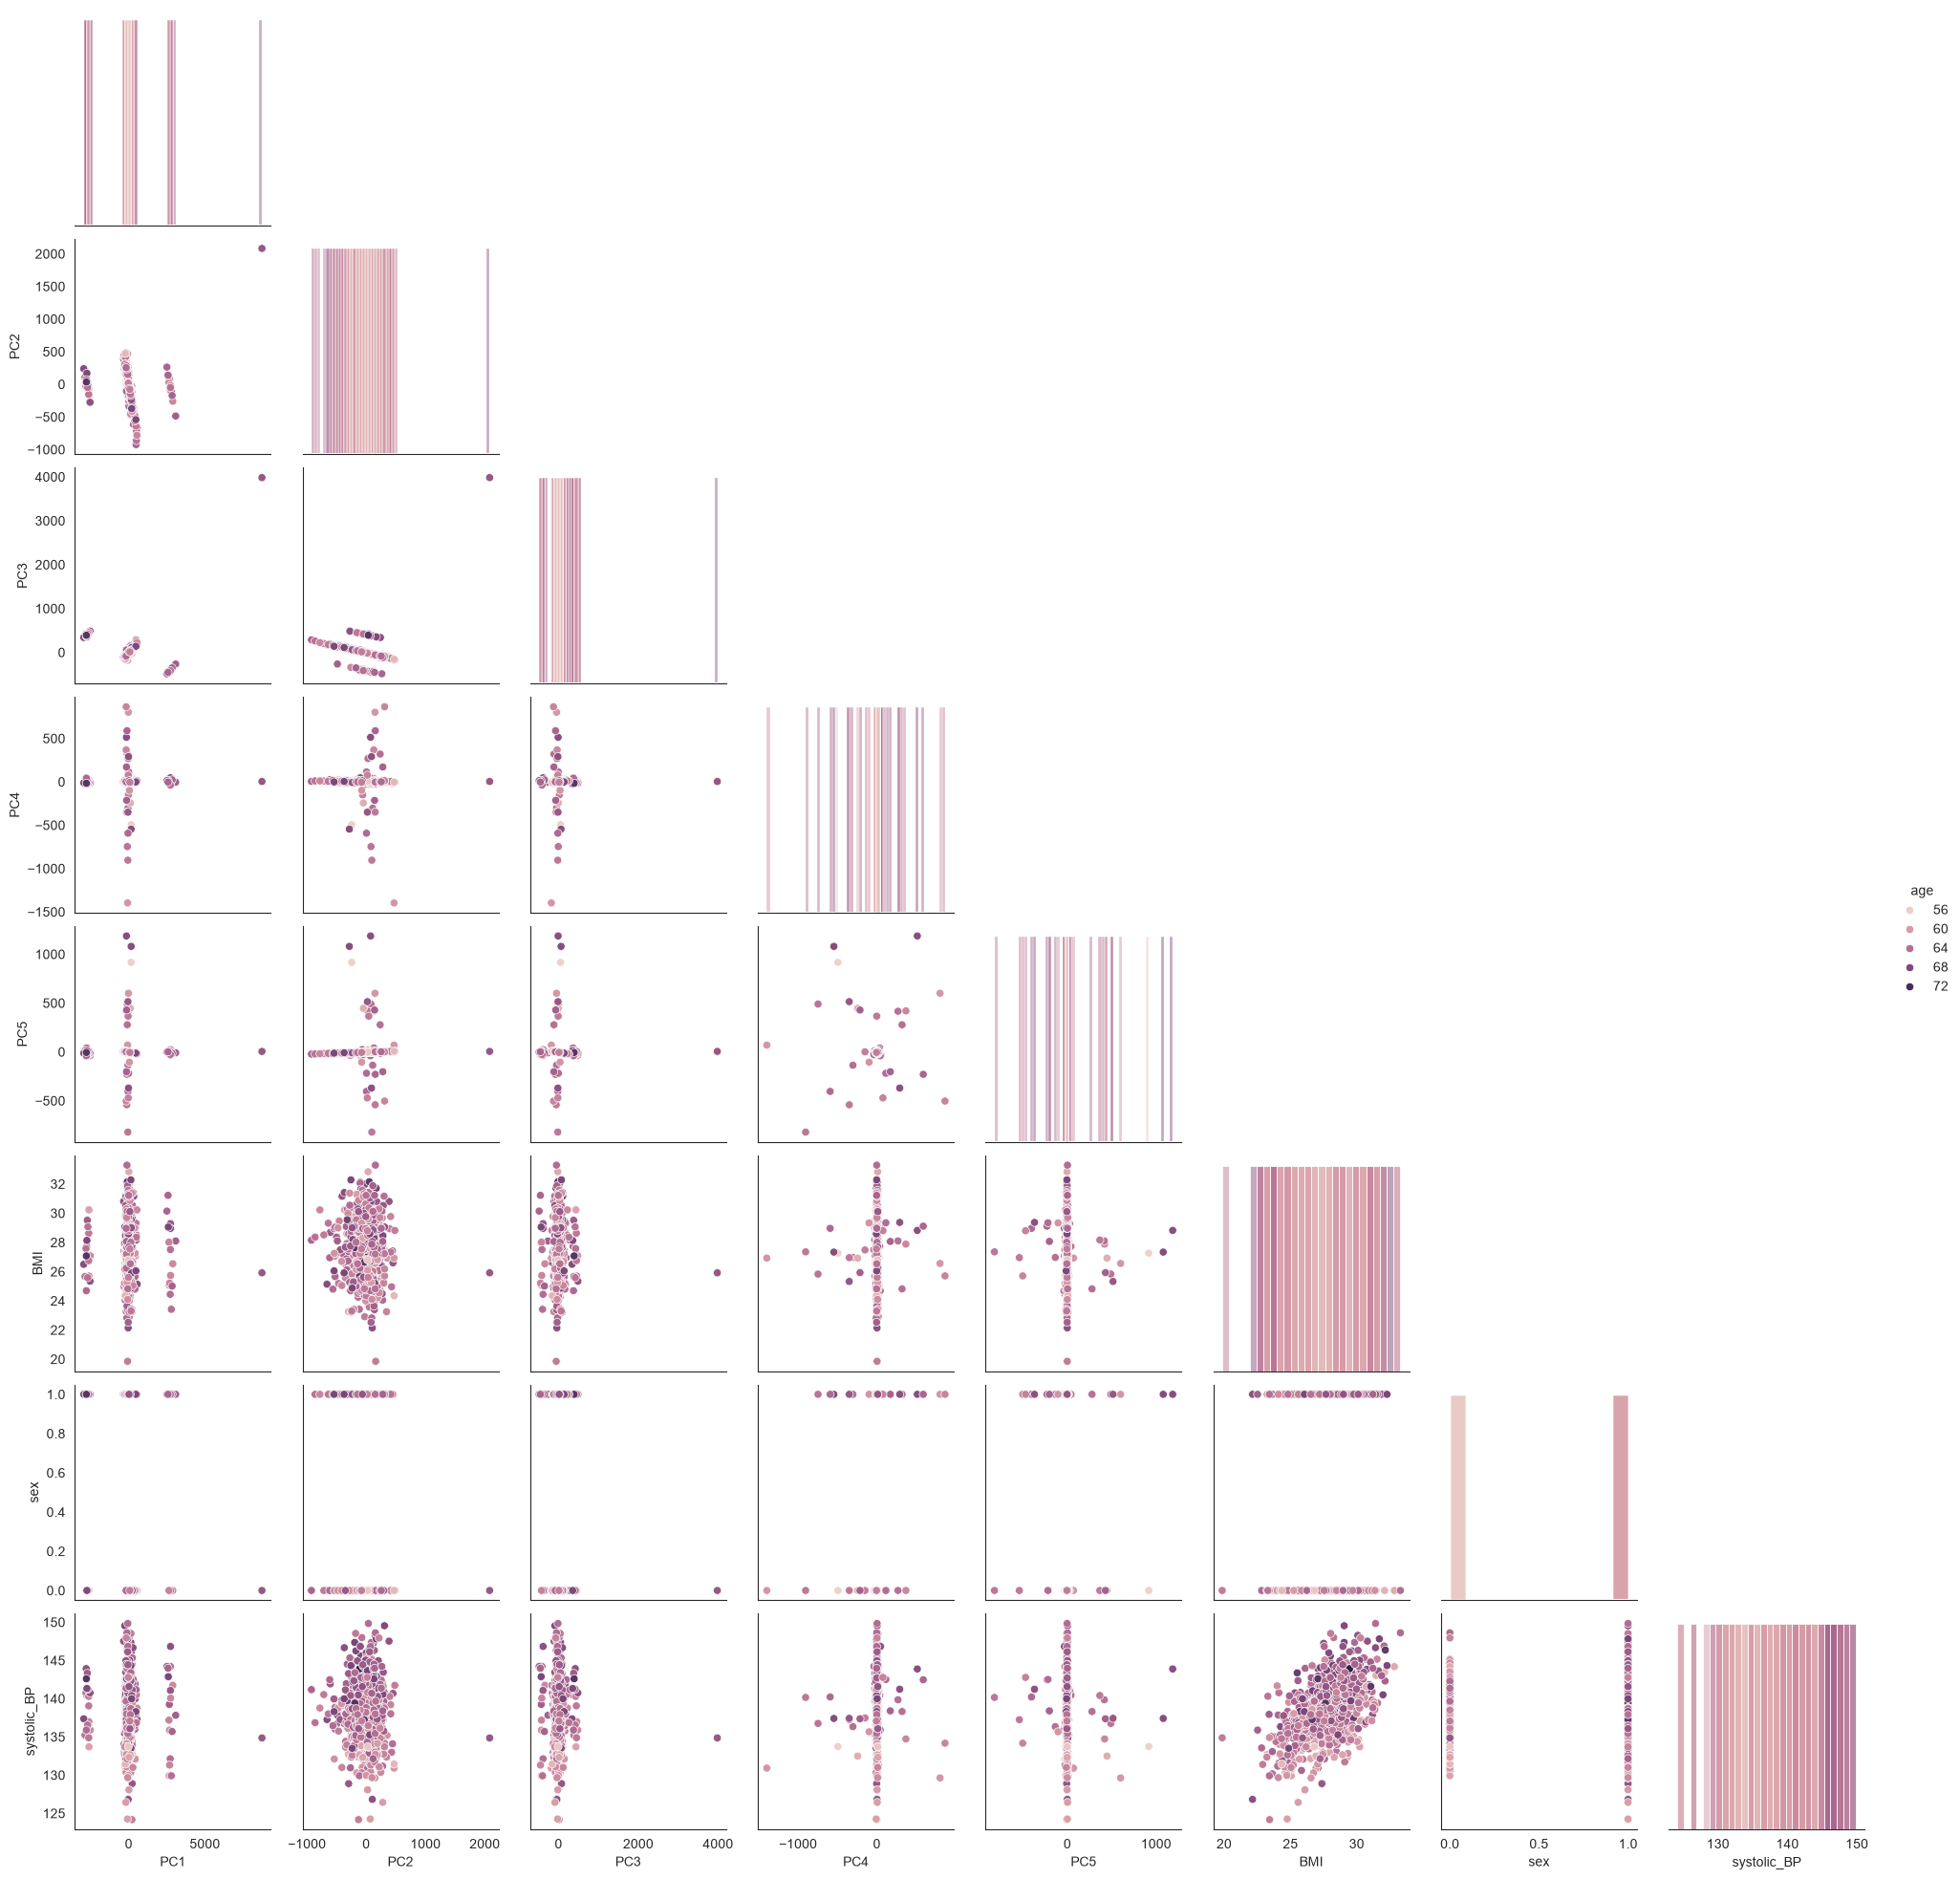

In [134]:
sns.set_style("white")
sns.pairplot(scores_df, diag_kind="hist", corner=True, hue='age')
plt.show()

KeyError: 'MI'

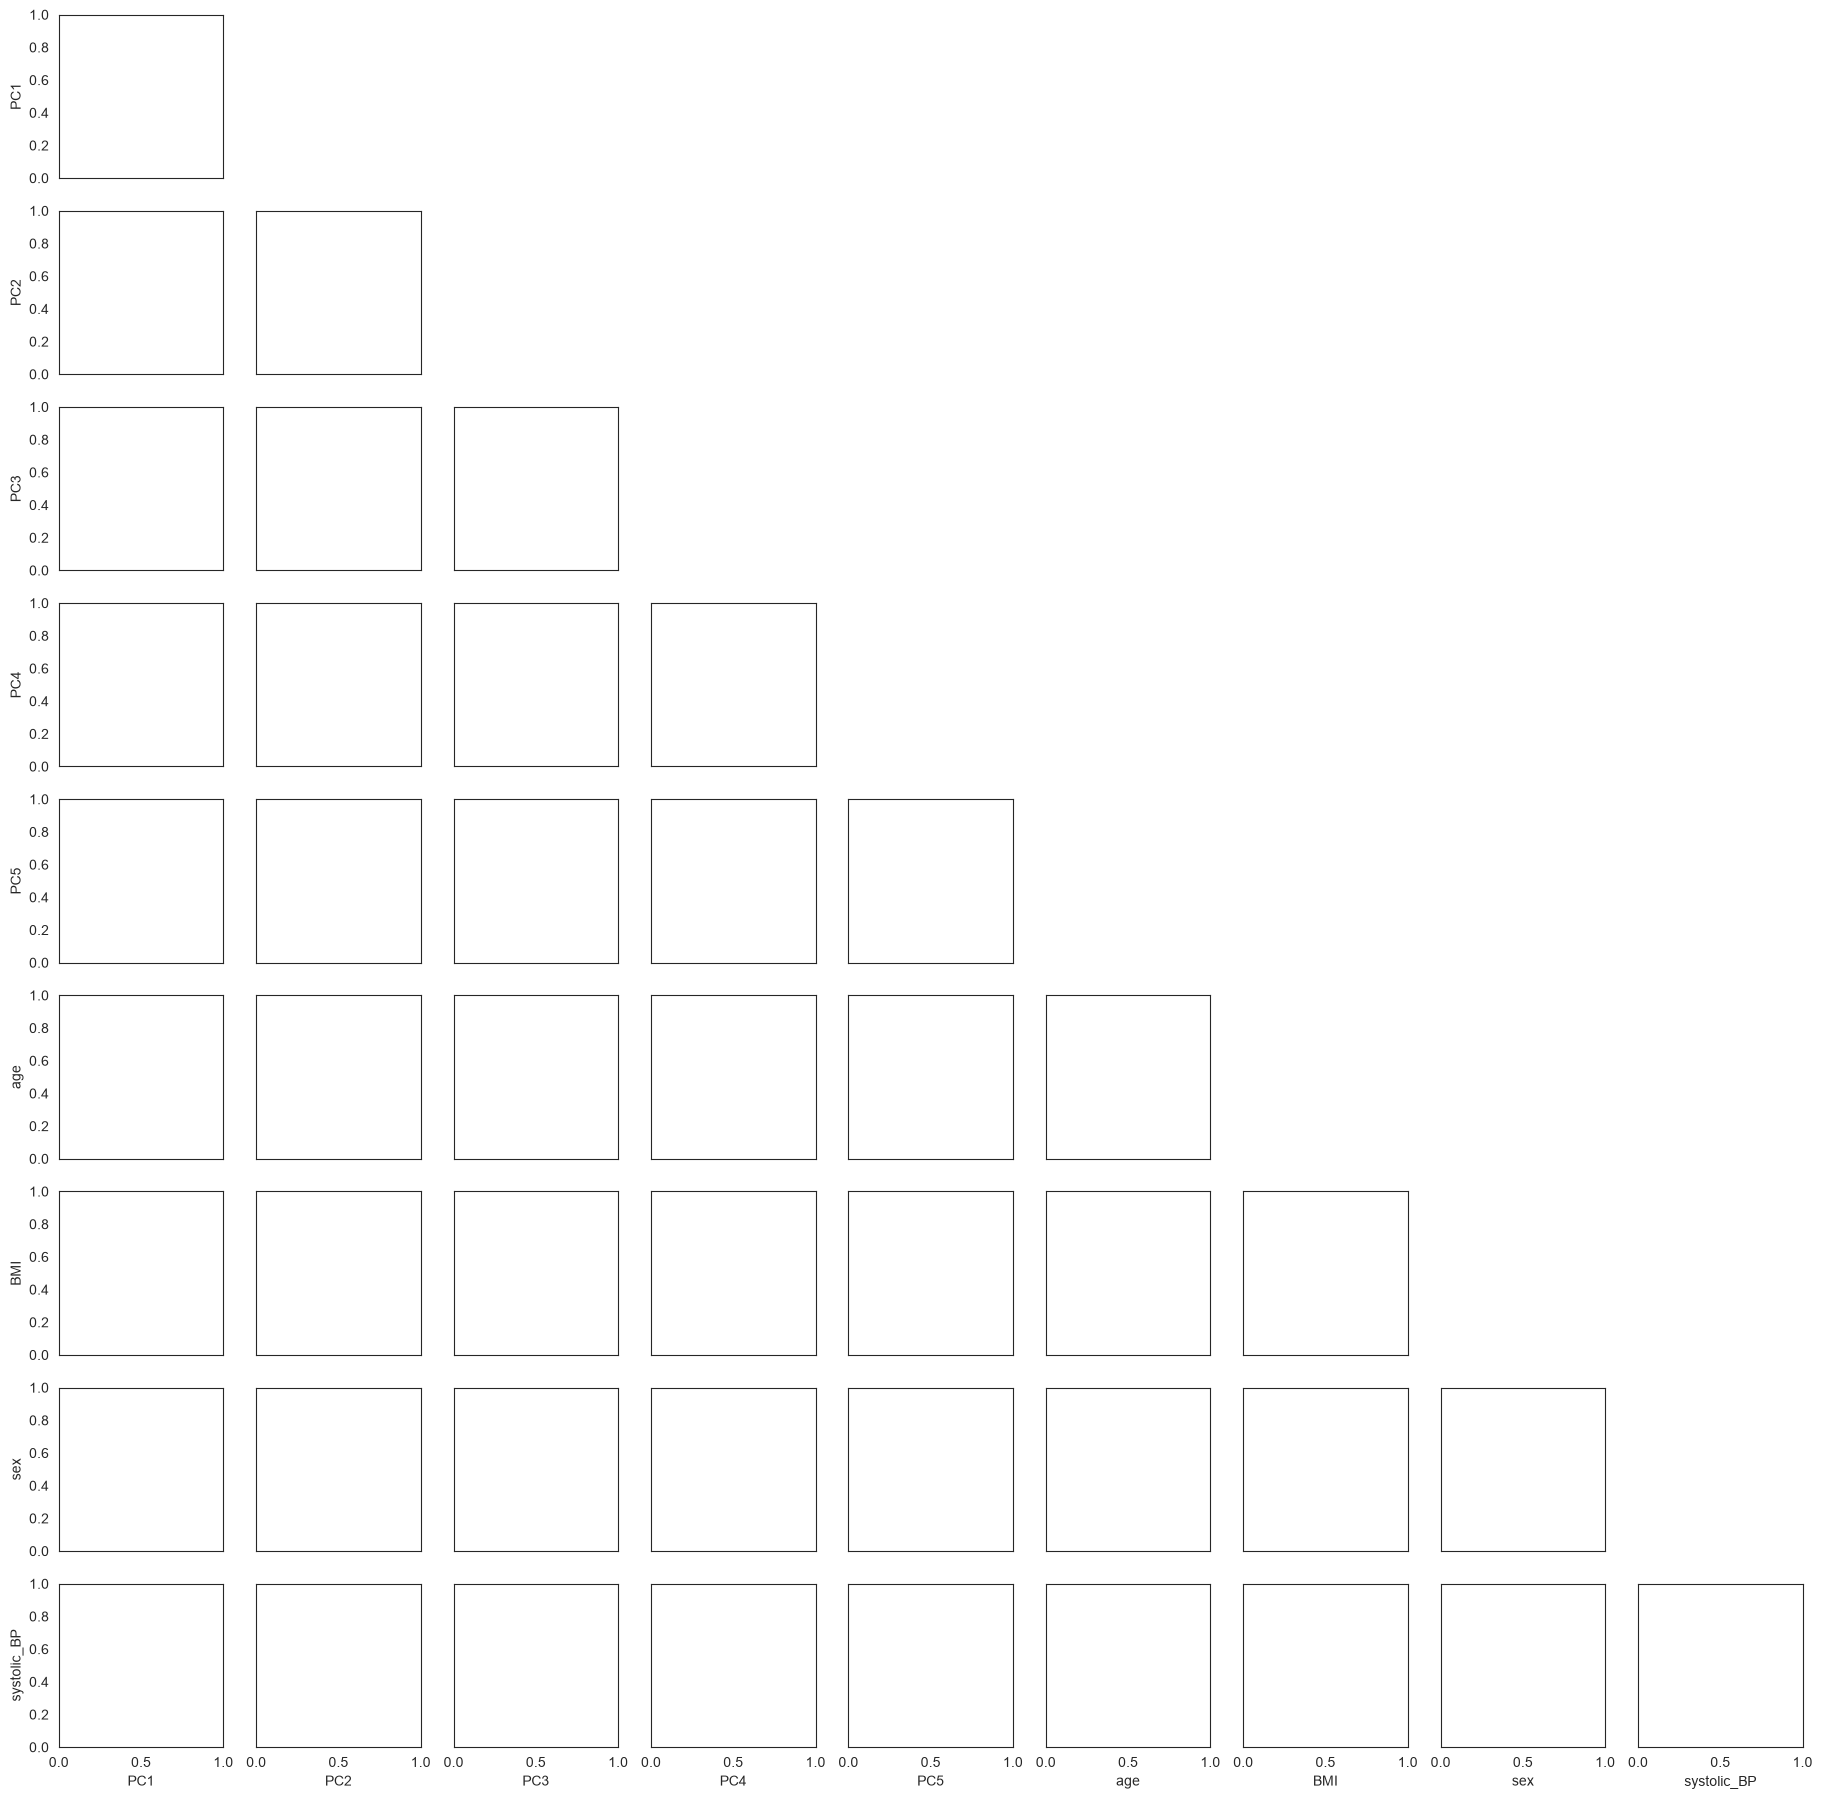

In [135]:
sns.set_style("white")
sns.pairplot(scores_df, diag_kind="hist", corner=True, hue='MI')
plt.show()

In [136]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(scores_df, tabular["MI"], test_size=0.2, random_state=42, stratify=tabular["MI"])


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['healthy','pMI']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['PC1','PC2','PC3',...,'BMI','sex','systolic_BP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [147]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score


def get_cv_f1(pipeline, X_train, y_train):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    f1_scores = []

    for i, (train_index, test_index) in enumerate(cv.split(X_train, y_train)):

        pipeline.fit(X_train.iloc[train_index], y_train.iloc[train_index])

        y_pred = pipeline.predict(X_train.iloc[test_index])
        y_proba = pipeline.predict_proba(X_train.iloc[test_index])

        report = classification_report(y_train.iloc[test_index], y_pred, output_dict=True)
        f1_scores.append(report['weighted avg']['f1-score'])

    return sum(f1_scores) / len(f1_scores)

In [ ]:
std_logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000))
])
std_logreg.fit(X_train, y_train)


print(get_cv_f1(std_logreg, X_train, y_train))

0.6880760458066133


In [ ]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(probability=True))
])

print(get_cv_f1(svm_pipeline, X_train, y_train))

0.6939719566971783


/Users/gharcombe/Documents/GitHub/introml_myocardial_infarction/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/gharcombe/Documents/GitHub/introml_myocardial_infarction/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/gharcombe/Documents/GitHub/introml_myocardial_infarction/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/gha

In [151]:
import xgboost as xgb

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

xgboost_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("xgboost", xgb.XGBClassifier(tree_method="hist", early_stopping_rounds=2))
])

print(get_cv_f1(xgboost_pipeline, X_train, le.fit_transform(y_train)))

AttributeError: 'numpy.ndarray' object has no attribute 'iloc'

In [141]:
y_pred = std_logreg.predict(X_test)
y_proba = std_logreg.predict_proba(X_test)

In [142]:

# After selecting your final model
print(classification_report(y_test, y_pred))
# print("AUROC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

     healthy       0.73      0.72      0.73        90
         pMI       0.73      0.73      0.73        90

    accuracy                           0.73       180
   macro avg       0.73      0.73      0.73       180
weighted avg       0.73      0.73      0.73       180

